# Лабораторная работа №4. Байесовская сеть

Цель: построить сеть зависимостей для пингвинов и проверить, как новые сведения меняют вероятности.

Данные: [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), Kristen Gorman и Palmer Station LTER, лицензия CC0. Использую официальный [penguins.csv](https://github.com/allisonhorst/palmerpenguins/blob/main/inst/extdata/penguins.csv). Он лежит рядом с ноутбуком; в JupyterLite нужно загрузить оба файла в одну папку.

## 1. Данные

Одна строка — наблюдение взрослого пингвина. Есть вид, остров, пол, масса, размеры клюва и ласта, год измерения. Для небольшой сети выберу четыре переменные.

| Переменная | Смысл |
|---|---|
| Species | Вид: Adelie, Chinstrap или Gentoo |
| Sex | Пол: female или male |
| Flipper | Категория длины ласта |
| Mass | Категория массы тела |

Вид и пол могут быть связаны с размерами тела. Длина ласта и масса также связаны с общим размером птицы. Остров, год и размеры клюва не включаю, чтобы не раздувать сеть и таблицы вероятностей.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import FancyArrowPatch

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
filename = 'penguins.csv'
data_path = next((p for p in (Path(filename), Path('bayesian') / filename) if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Загрузите penguins.csv в одну папку с lab04.ipynb.')
data = pd.read_csv(data_path)
print('Размер таблицы:', data.shape)
print('Полных повторов:', data.duplicated().sum())
display(pd.DataFrame({'Тип': data.dtypes.astype(str), 'Пропуски': data.isna().sum()}))
columns = ['species', 'sex', 'flipper_length_mm', 'body_mass_g']
clean = data.dropna(subset=columns).copy()
print(f'Полных наблюдений для сети: {len(clean)}; исключено: {len(data) - len(clean)}')
display(pd.crosstab(clean['species'], clean['sex']))

Размер таблицы: (344, 8)
Полных повторов: 0


,Тип,Пропуски
species,object,0
island,object,0
bill_length_mm,float64,2
bill_depth_mm,float64,2
flipper_length_mm,float64,2
body_mass_g,float64,2
sex,object,11
year,int64,0


Полных наблюдений для сети: 333; исключено: 11


sex,female,male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


## 2. Подготовка и дискретизация

В таблице 344 строки. Для выбранных переменных не хватает пола у 11 птиц, у двух из них также нет измерений. Оставляю 333 полных наблюдения. Подставлять наиболее частый пол не буду: это могло бы исказить зависимости размеров от пола. Удаление пропусков тоже может сместить результат, если они возникли неслучайно.

Длину ласта разделю на Short (<200 мм) и Long (от 200 мм). Массу — на Light (<3500 г), Medium (от 3500 до 4500 г) и Heavy (от 4500 г). Это простые округлённые границы для учебного анализа, а не биологические нормы. Они сохраняют понятный смысл и оставляют мало состояний.

Сеть описывает этот набор наблюдений. Границы фиксированы вручную, параметры оцениваются по всем полным строкам; отдельного теста на новых птицах здесь нет. Повторы категорий после дискретизации нормальны, их не удаляю.

,Species
Species,
Adelie,146
Chinstrap,68
Gentoo,119


,Sex
Sex,
female,165
male,168


,Flipper
Flipper,
Short,185
Long,148


,Mass
Mass,
Light,68
Medium,150
Heavy,115


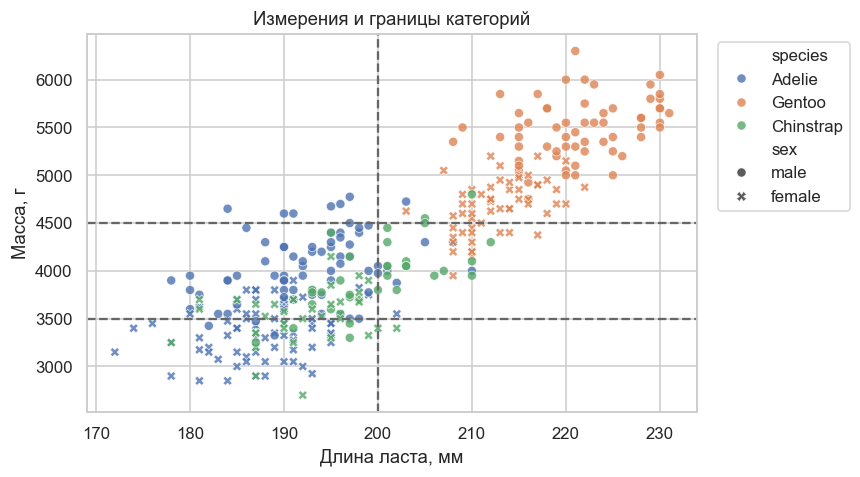

In [2]:
frame = pd.DataFrame({
    'Species': clean['species'],
    'Sex': clean['sex'],
    'Flipper': pd.cut(clean['flipper_length_mm'], [-np.inf, 200, np.inf],
                      labels=['Short', 'Long'], right=False),
    'Mass': pd.cut(clean['body_mass_g'], [-np.inf, 3500, 4500, np.inf],
                   labels=['Light', 'Medium', 'Heavy'], right=False),
})
states = {
    'Species': ['Adelie', 'Chinstrap', 'Gentoo'],
    'Sex': ['female', 'male'],
    'Flipper': ['Short', 'Long'],
    'Mass': ['Light', 'Medium', 'Heavy'],
}
for node, values in states.items():
    display(frame[node].value_counts().reindex(values).to_frame(node))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=clean, x='flipper_length_mm', y='body_mass_g', hue='species',
                style='sex', ax=ax, alpha=0.8)
ax.axvline(200, color='0.4', linestyle='--')
for border in [3500, 4500]:
    ax.axhline(border, color='0.4', linestyle='--')
ax.set(xlabel='Длина ласта, мм', ylabel='Масса, г', title='Измерения и границы категорий')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

После обработки осталось 146 Adelie, 68 Chinstrap и 119 Gentoo; 165 самок и 168 самцов. В категориях массы 68 Light, 150 Medium и 115 Heavy, ластов — 185 Short и 148 Long. Отдельные состояния не редкие, но их сочетания могут быть редкими.

На графике Gentoo в основном крупнее и имеют более длинные ласты. У Adelie и Chinstrap группы заметно пересекаются. Простая граница по длине не определяет вид однозначно.

## 3. Вопросы к сети

До построения графа задам вопросы:

1. Как изменится вероятность большой массы, если известно, что пингвин относится к Gentoo?
2. Какова вероятность большой массы у самца Adelie по сравнению с общей вероятностью?
3. Как знание о длинном ласте изменит вероятность того, что птица относится к Gentoo?

Дополнительно буду по очереди узнавать вид Adelie, мужской пол и длинный ласт и смотреть всё распределение массы.

## 4. Структура графа

Species и Sex влияют на распределение Flipper и Mass в модели: разные виды и полы отличаются размерами. Добавлю Flipper → Mass, чтобы длина ласта давала сведения о массе и внутри одного вида и пола. Это направление удобно для выбранного вопроса о массе; оно не означает, что удлинение ласта само по себе увеличивает массу.

Species и Sex считаю независимыми корнями. Это упрощение: в выборке могут быть различия в долях полов по видам. Граф задаю по смыслу переменных, а не по порогу корреляции.

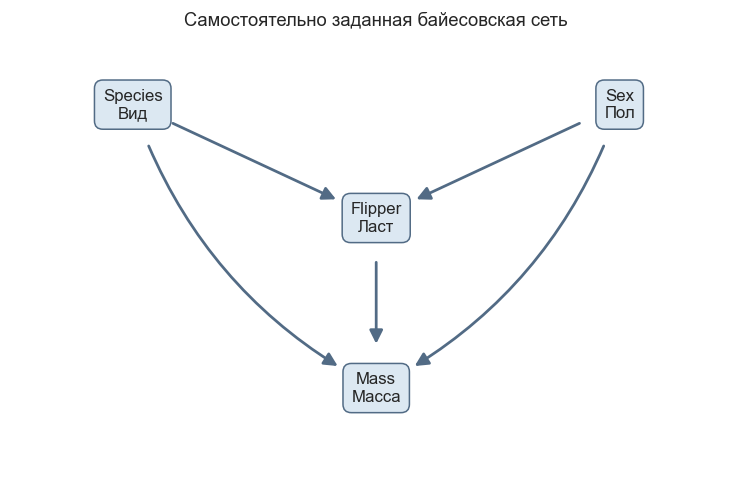

In [3]:
parents = {
    'Species': [],
    'Sex': [],
    'Flipper': ['Species', 'Sex'],
    'Mass': ['Species', 'Sex', 'Flipper'],
}
nodes = list(parents)
edges = [(parent, node) for node, sources in parents.items() for parent in sources]
# Родители идут раньше детей: такой порядок исключает направленные циклы.
assert all(nodes.index(parent) < nodes.index(child) for parent, child in edges)
positions = {'Species': (-1.2, 1), 'Sex': (1.2, 1), 'Flipper': (0, 0.2), 'Mass': (0, -1)}
labels = {'Species': 'Species\nВид', 'Sex': 'Sex\nПол', 'Flipper': 'Flipper\nЛаст', 'Mass': 'Mass\nМасса'}
fig, ax = plt.subplots(figsize=(7, 4.5))
for source, target in edges:
    bend = 0.2 if (source, target) == ('Species', 'Mass') else -0.2 if (source, target) == ('Sex', 'Mass') else 0
    ax.add_patch(FancyArrowPatch(positions[source], positions[target], arrowstyle='-|>',
                                mutation_scale=18, shrinkA=29, shrinkB=29,
                                connectionstyle=f'arc3,rad={bend}', color='#526b85', linewidth=1.8))
for node, (x, y) in positions.items():
    ax.text(x, y, labels[node], ha='center', va='center', fontsize=11,
            bbox={'boxstyle': 'round,pad=0.5', 'facecolor': '#dce8f2', 'edgecolor': '#526b85'})
ax.set(xlim=(-1.8, 1.8), ylim=(-1.55, 1.5), title='Самостоятельно заданная байесовская сеть')
ax.axis('off')
plt.tight_layout()
plt.show()

Совместная вероятность раскладывается так:

P(Species, Sex, Flipper, Mass) = P(Species) · P(Sex) · P(Flipper | Species, Sex) · P(Mass | Species, Sex, Flipper).

Всего 3 × 2 × 2 × 3 = 36 сочетаний состояний. Поэтому точный вывод можно сделать полным перебором на pandas и NumPy, без дополнительных библиотек для сетей.

## 5. Условные вероятности

Для каждого узла посчитаю частоты при фиксированных родителях. Использую сглаживание Лапласа: P = (число подходящих строк + 1) / (число строк с этими родителями + число состояний узла).

Так редкое сочетание не получает нулевую вероятность только из-за малого набора данных. Если сочетание родителей вообще не встречалось, распределение будет равномерным. Это допущение сглаживания, а не наблюдение. Вместе с вероятностями показываю N — число исходных строк.

In [4]:
def fit_network(table, structure, alpha=1.0):
    cpds = {}
    support = {}
    for node, sources in structure.items():
        cpds[node] = {}
        support[node] = {}
        for combination in product(*(states[parent] for parent in sources)):
            subset = table
            for parent, value in zip(sources, combination):
                subset = subset[subset[parent] == value]
            counts = subset[node].value_counts().reindex(states[node], fill_value=0)
            cpds[node][combination] = (counts.to_numpy() + alpha) / (len(subset) + alpha * len(states[node]))
            support[node][combination] = len(subset)
    return cpds, support


def cpd_table(node, cpds, support, structure):
    rows = []
    for combination, probabilities in cpds[node].items():
        row = dict(zip(structure[node], combination))
        row['N'] = support[node][combination]
        row.update(dict(zip(states[node], probabilities)))
        rows.append(row)
    return pd.DataFrame(rows)


cpds, support = fit_network(frame, parents)
for node in ['Flipper', 'Mass']:
    print(f'P({node} | {", ".join(parents[node])})')
    display(cpd_table(node, cpds, support, parents).round(4))
    counts = np.array(list(support[node].values()))
    print(f'Комбинаций родителей: {len(counts)}, без наблюдений: {(counts == 0).sum()}, с N < 5: {(counts < 5).sum()}')

check_rows = []
for species, sex, flipper in [('Adelie', 'male', 'Long'), ('Gentoo', 'female', 'Long')]:
    subset = frame[(frame['Species'] == species) & (frame['Sex'] == sex) & (frame['Flipper'] == flipper)]
    check_rows.append({
        'Species': species, 'Sex': sex, 'Flipper': flipper, 'N': len(subset),
        'Частота Heavy': subset['Mass'].eq('Heavy').mean(),
        'CPT Heavy': cpds['Mass'][(species, sex, flipper)][states['Mass'].index('Heavy')],
    })
cpd_check = pd.DataFrame(check_rows)
display(cpd_check.round(4))

P(Flipper | Species, Sex)


,Species,Sex,N,Short,Long
0,Adelie,female,73,0.9733,0.0267
1,Adelie,male,73,0.8800,0.1200
2,Chinstrap,female,34,0.9167,0.0833
3,Chinstrap,male,34,0.4722,0.5278
4,Gentoo,female,58,0.0167,0.9833
5,Gentoo,male,61,0.0159,0.9841


Комбинаций родителей: 6, без наблюдений: 0, с N < 5: 0
P(Mass | Species, Sex, Flipper)


,Species,Sex,Flipper,N,Light,Medium,Heavy
0,Adelie,female,Short,72,0.6533,0.3333,0.0133
1,Adelie,female,Long,1,0.2500,0.5000,0.2500
2,Adelie,male,Short,65,0.0588,0.8235,0.1176
3,Adelie,male,Long,8,0.0909,0.7273,0.1818
4,Chinstrap,female,Short,32,0.3429,0.6286,0.0286
5,Chinstrap,female,Long,2,0.6000,0.2000,0.2000
6,Chinstrap,male,Short,16,0.2632,0.6842,0.0526
7,Chinstrap,male,Long,18,0.0476,0.7619,0.1905
8,Gentoo,female,Short,0,0.3333,0.3333,0.3333
9,Gentoo,female,Long,58,0.0164,0.2623,0.7213


Комбинаций родителей: 12, без наблюдений: 2, с N < 5: 4


,Species,Sex,Flipper,N,Частота Heavy,CPT Heavy
0,Adelie,male,Long,8,0.1250,0.1818
1,Gentoo,female,Long,58,0.7414,0.7213


У Gentoo вероятность Long близка к 0,98 для обоих полов, а у Adelie она намного ниже. Для массы есть 12 сочетаний родителей, два вообще не встречались: Gentoo с коротким ластом. Ещё два сочетания содержат только 1–2 наблюдения. Всего у четырёх строк CPT массы N < 5, поэтому их оценки особенно сильно зависят от сглаживания.

У самцов Adelie с длинным ластом всего 8 наблюдений: частота Heavy равна 1/8 = 0,125, а после сглаживания — 2/11 = 0,1818. У самок Gentoo с длинным ластом данных больше (58), и отличие меньше: 0,7414 против 0,7213. Сглаживание не всегда уменьшает вероятность: оно сдвигает её к равномерной, здесь 1/3.

Необычные ненулевые вероятности коротких ластов у Gentoo появились из псевдосчётчиков. Они не доказывают, что такие птицы наблюдались в этой выборке.

## 6. Вероятностный вывод

Для каждого полного состояния перемножаю вероятности из таблиц узлов. При запросе оставляю состояния, совместимые с evidence, суммирую по неизвестным переменным и нормирую результат. Неизвестная переменная не заменяется нулём: учитываются все её возможные состояния.

In [5]:
def make_joint(cpds, structure):
    names = list(structure)
    rows = []
    for combination in product(*(states[node] for node in names)):
        assignment = dict(zip(names, combination))
        probability = 1.0
        for node, sources in structure.items():
            parent_values = tuple(assignment[parent] for parent in sources)
            state_index = states[node].index(assignment[node])
            probability *= cpds[node][parent_values][state_index]
        rows.append({**assignment, 'p': probability})
    return pd.DataFrame(rows)


def query(joint, target, evidence=None):
    matching = joint
    for node, value in (evidence or {}).items():
        if value not in states[node]:
            raise ValueError(f'Неизвестное состояние {node}: {value}')
        matching = matching[matching[node] == value]
    total = matching['p'].sum()
    if total <= 0:
        raise ValueError('Вероятность evidence равна нулю.')
    return matching.groupby(target)['p'].sum().reindex(states[target], fill_value=0) / total


joint = make_joint(cpds, parents)
assert np.isclose(joint['p'].sum(), 1)
assert all(np.isclose(values.sum(), 1) for node in cpds.values() for values in node.values())
questions = [
    ('Масса Gentoo', 'Mass', 'Heavy', {'Species': 'Gentoo'}),
    ('Масса самца Adelie', 'Mass', 'Heavy', {'Species': 'Adelie', 'Sex': 'male'}),
    ('Вид по длинному ласту', 'Species', 'Gentoo', {'Flipper': 'Long'}),
]
query_rows = []
for title, target, state, evidence in questions:
    subset = frame
    for node, value in evidence.items():
        subset = subset[subset[node] == value]
    query_rows.append({
        'Вопрос': title, 'До evidence': query(joint, target)[state],
        'После evidence': query(joint, target, evidence)[state],
        'Частота в данных': subset[target].eq(state).mean(), 'N evidence': len(subset),
    })
query_results = pd.DataFrame(query_rows).set_index('Вопрос')
display(query_results.round(4))

,До evidence,После evidence,Частота в данных,N evidence
Вопрос,,,,
Масса Gentoo,0.3485,0.8378,0.8739,119
Масса самца Adelie,0.3485,0.1253,0.1096,73
Вид по длинному ласту,0.3571,0.7864,0.8041,148


Знание вида Gentoo повышает модельную вероятность Heavy с 0,3485 до 0,8378. Это согласуется с их большей массой на графике.

Для самца Adelie вероятность Heavy равна 0,1253 — ниже общей 0,3485, потому что в общей выборке есть более крупные Gentoo. Сам по себе мужской пол не означает, что птица тяжелее всех остальных видов.

При длинном ласте вероятность Gentoo растёт с 0,3571 до 0,7864. Здесь информация идёт от наблюдаемого потомка Flipper к Species: по измерению уточняется предположение о виде.

Модельные вероятности могут отличаться от частот из-за сглаживания и принятых независимостей графа. Это оценки для этой выборки, а не точные вероятности для всех пингвинов.

## 7. Последовательное добавление evidence

Целевая переменная — Mass. Сначала ничего не известно, затем узнаю вид Adelie, мужской пол и длинный ласт. Каждый шаг добавляет сведения о родителях Mass.

Mass,Light,Medium,Heavy
Нет сведений,0.2132,0.4382,0.3485
Adelie,0.3500,0.5770,0.0730
"Adelie, male",0.0627,0.8120,0.1253
"Adelie, male, Long",0.0909,0.7273,0.1818


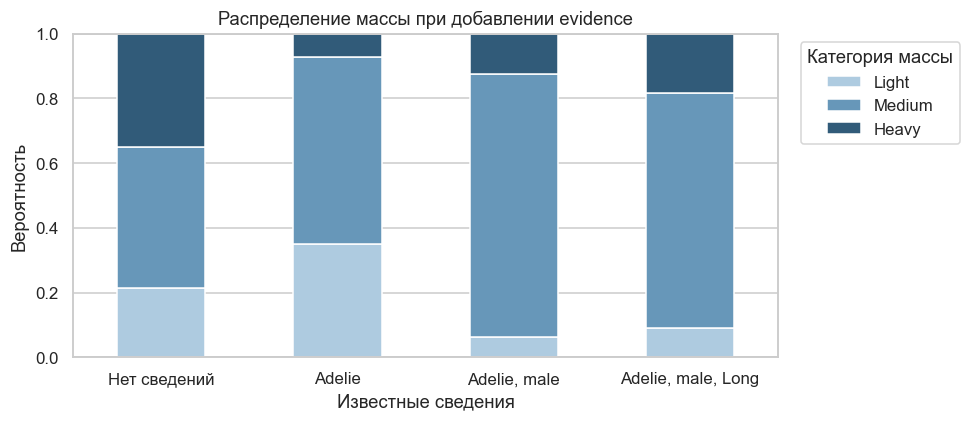

In [6]:
evidence_steps = [
    ('Нет сведений', {}),
    ('Adelie', {'Species': 'Adelie'}),
    ('Adelie, male', {'Species': 'Adelie', 'Sex': 'male'}),
    ('Adelie, male, Long', {'Species': 'Adelie', 'Sex': 'male', 'Flipper': 'Long'}),
]
evidence_results = pd.DataFrame({label: query(joint, 'Mass', evidence) for label, evidence in evidence_steps}).T
display(evidence_results.round(4))
ax = evidence_results.plot.bar(stacked=True, rot=0, figsize=(9, 4), color=['#aecbe0', '#6797b9', '#315b79'])
ax.set(ylabel='Вероятность', xlabel='Известные сведения', ylim=(0, 1), title='Распределение массы при добавлении evidence')
ax.legend(title='Категория массы', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Вероятность Heavy меняется так: 0,3485 без сведений → 0,0730 при Species=Adelie → 0,1253 при добавлении male → 0,1818 при добавлении Long. Сначала вид снижает вероятность большой массы относительно общей популяции, затем пол и длина ласта повышают её внутри выбранного вида.

Изменение не обязано быть монотонным: каждый новый факт уточняет контекст. В последней группе только 8 наблюдений, поэтому итог заметно зависит от сглаживания.

## 8. Удаление ребра

Удалю Sex → Mass, сохранив остальные узлы и рёбра. Заново оценю таблицы по тем же строкам с тем же сглаживанием. Сравню распределение массы для самца Adelie с длинным ластом.

В новой сети остаётся путь Sex → Flipper → Mass. Но в выбранном запросе Flipper уже известен, как и Species. Поэтому дополнительное знание пола больше не должно менять распределение Mass в этой модели.

In [7]:
reduced_parents = {node: sources.copy() for node, sources in parents.items()}
reduced_parents['Mass'].remove('Sex')
reduced_cpds, reduced_support = fit_network(frame, reduced_parents)
reduced_joint = make_joint(reduced_cpds, reduced_parents)
comparison_evidence = evidence_steps[-1][1]
structure_results = pd.DataFrame({
    'Исходная сеть': query(joint, 'Mass', comparison_evidence),
    'Без Sex → Mass': query(reduced_joint, 'Mass', comparison_evidence),
})
structure_results['Изменение'] = structure_results['Без Sex → Mass'] - structure_results['Исходная сеть']
display(structure_results.round(4))
without_sex = {key: value for key, value in comparison_evidence.items() if key != 'Sex'}
assert np.allclose(query(reduced_joint, 'Mass', comparison_evidence), query(reduced_joint, 'Mass', without_sex))
print('После удаления ребра пол не меняет этот запрос при известных Species и Flipper.')

,Исходная сеть,Без Sex → Mass,Изменение
Mass,,,
Light,0.0909,0.0833,-0.0076
Medium,0.7273,0.7500,0.0227
Heavy,0.1818,0.1667,-0.0152


После удаления ребра пол не меняет этот запрос при известных Species и Flipper.


После удаления Sex → Mass вероятность Heavy в выбранном запросе изменилась с 0,1818 до 0,1667, то есть примерно на -1,52 процентного пункта. Теперь таблица массы объединяет оба пола при одинаковых виде и длине ласта. Изменение небольшое, но оно показывает зависимость ответа от структуры и от того, какие наблюдения объединяются при оценке CPT.

Проверка в коде подтверждает условную независимость: в сокращённой сети при известных Species и Flipper добавление Sex не меняет ответ. В исходной сети прямое ребро позволяло полу давать дополнительную информацию.

## 9. Вывод

По измерениям можно уточнять распределения: Gentoo чаще имеют большую массу, а длинный ласт повышает вероятность Gentoo. Последовательное добавление evidence изменило распределение массы, а удаление ребра изменило тот же запрос даже при неизменных исходных данных. Сеть позволяет явно записать эти зависимости и проверить следствия выбранной структуры.

Построенную сеть не считаю доказанной причинной моделью. Стрелки задают выбранное разложение вероятностей. Направление связи между длиной ласта и массой нельзя уверенно установить только по таким наблюдениям; на оба признака могут влиять общие причины. Запрос с evidence означает наблюдение, а не вмешательство.

Ограничения: небольшая выборка, удаление строк с пропусками, грубые категории, редкие сочетания родителей и предположение о независимости вида и пола. Структура задана вручную и не проверена на новых данных. Сглаживание помогает считать вероятности, но не заменяет отсутствующие наблюдения.

Проверено с Python 3.9, NumPy 1.26.4, pandas 2.3.3, Matplotlib 3.9.4 и seaborn 0.13.2. Ячейки запускать сверху вниз.